# GNN para estações meteorológicas — grafo_v6 (PyTorch Geometric)

Versão adaptada para **PyTorch Geometric**, com seleção automática de dispositivo para **CUDA**, **MPS/Metal (Apple Silicon)** e CPU.


In [1]:
import os
import re
import glob
import math
import unicodedata
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx

from torch_geometric.data import Data
from torch_geometric.nn import MessagePassing

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    BACKEND = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    BACKEND = "mps"
else:
    DEVICE = torch.device("cpu")
    BACKEND = "cpu"

print("Device:", DEVICE)
print("Backend:", BACKEND)

/home/viniz0r/Documentos/IT_novo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Backend: cuda


## 1. Carregamento do grafo


In [2]:
G = nx.read_graphml("001.graphml")

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))
print("Primeiros nós:", list(G.nodes())[:10])


Grafo com 35 nós e 86 arestas. Direcionado: False
Primeiros nós: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 2. Funções auxiliares geográficas e visualização do grafo


Coordenadas carregadas para 35 nós.
Exemplos:
  Nó  0: (-23.43640996621655, -46.90925768439525)
  Nó 19: (-23.546111111111113, -46.63194444444444)
  Nó 33: (-23.559765113146554, -46.73399418127595)
  Nó 34: (-23.496111111111112, -46.61972222222222)

Todos os nós têm coordenadas explícitas. ✅

Pesos geográficos calculados para 86 arestas.
  Distância mín : 0.1000 km
  Distância máx : 28.6249 km
  Peso mín      : 0.034935  (nós mais distantes)
  Peso máx      : 10.000000  (nós mais próximos)
  Peso médio    : 0.277984

Amostra de arestas com distância e peso usados no grafo:
  0 -> 1: distância = 18.8461 km | peso = 0.053061
  0 -> 17: distância = 22.9402 km | peso = 0.043592
  0 -> 27: distância = 17.2435 km | peso = 0.057993
  1 -> 2: distância = 3.8313 km | peso = 0.261006
  1 -> 17: distância = 5.6029 km | peso = 0.178478


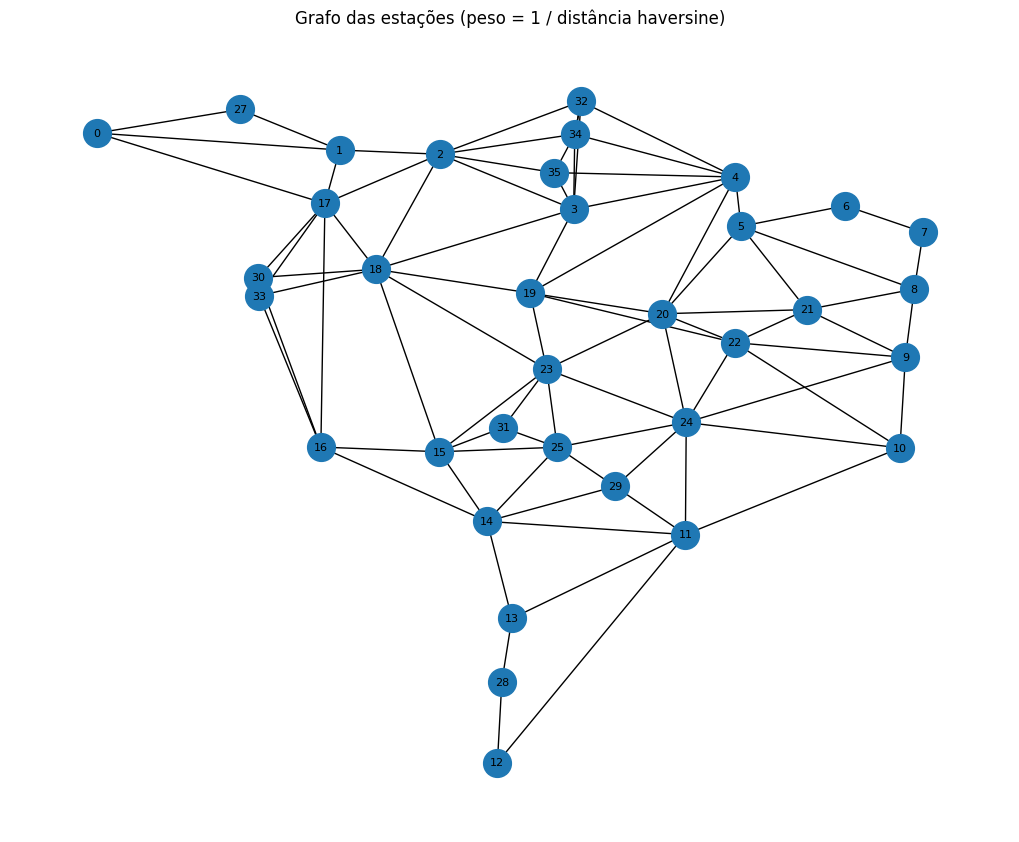

In [3]:
def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = float(degrees) + float(minutes) / 60 + float(seconds) / 3600
    if str(direction).upper() in ["S", "W", "O"]:
        decimal *= -1
    return decimal


def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c


# Coordenadas de todas as estações
# Formato DMS: (graus, min, seg, direção) para lat e lon
_COORDS_DMS = {
    '1':  (23, 28, 46, 'S', 46, 43, 50, 'W'),
    '2':  (23, 29, 13, 'S', 46, 41, 38, 'W'),
    '3':  (23, 28, 38, 'S', 46, 36, 26, 'W'),
    '4':  (23, 30, 33, 'S', 46, 36, 26, 'W'),
    '5':  (23, 31, 16, 'S', 46, 31, 24, 'W'),
    '6':  (23, 30, 10, 'S', 46, 26, 21, 'W'),
    '7':  (23, 30, 12, 'S', 46, 23, 10, 'W'),
    '8':  (23, 32,  6, 'S', 46, 27, 16, 'W'),
    '9':  (23, 36,  0, 'S', 46, 28, 50, 'W'),
    '10': (23, 40,  4, 'S', 46, 27, 39, 'W'),
    '11': (23, 46, 44, 'S', 46, 31, 42, 'W'),
    '12': (23, 56, 11, 'S', 46, 42, 31, 'W'),
    '13': (23, 40, 58, 'S', 46, 42, 41, 'W'),
    '14': (23, 35, 16, 'S', 46, 43,  0, 'W'),
    '15': (23, 41, 19, 'S', 46, 46, 14, 'W'),
    '16': (23, 37, 58, 'S', 46, 45, 58, 'W'),
    '17': (23, 31, 28, 'S', 46, 42, 21, 'W'),
    '18': (23, 33, 57, 'S', 46, 41, 22, 'W'),
    '19': (23, 32, 46, 'S', 46, 37, 55, 'W'),
    '20': (23, 33, 46, 'S', 46, 35, 52, 'W'),
    '21': (23, 34,  7, 'S', 46, 32, 49, 'W'),
    '22': (23, 35, 33, 'S', 46, 34, 26, 'W'),
    '23': (23, 35, 18, 'S', 46, 38,  4, 'W'),
    '24': (23, 35, 20, 'S', 46, 36, 19, 'W'),
    '25': (23, 39,  8, 'S', 46, 38, 51, 'W'),
    '27': (23, 24, 35, 'S', 46, 44, 34, 'W'),
    '28': (23, 49, 31, 'S', 46, 42, 20, 'W'),
    '29': (23, 40, 30, 'S', 46, 39, 17, 'W'),
    '30': (23, 34,  8, 'S', 46, 43, 45, 'W'),
    '31': (23, 38, 33, 'S', 46, 41, 58, 'W'),
    '32': (23, 24, 44, 'S', 46, 35, 14, 'W'),
    '34': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '35': (23, 29, 46, 'S', 46, 37, 11, 'W'),
}

_COORDS_DEC = {
    '33': (-23.559765113146554, -46.73399418127595),
    '0':  (-23.43640996621655,  -46.90925768439525),
}

COORDS = {}
for node, dms in _COORDS_DMS.items():
    lat = dms_to_decimal(dms[0], dms[1], dms[2], dms[3])
    lon = dms_to_decimal(dms[4], dms[5], dms[6], dms[7])
    COORDS[node] = (lat, lon)
for node, dec in _COORDS_DEC.items():
    COORDS[node] = dec

print(f"Coordenadas carregadas para {len(COORDS)} nós.")
print("Exemplos:")
for n in ['0', '19', '33', '34']:
    if n in COORDS:
        print(f"  Nó {n:>2}: {COORDS[n]}")

nos_sem_coordenada = []
for node in G.nodes():
    node_str = str(node)
    if node_str in COORDS:
        G.nodes[node]['lat'] = COORDS[node_str][0]
        G.nodes[node]['lon'] = COORDS[node_str][1]
    else:
        try:
            G.nodes[node]['lat'] = float(G.nodes[node].get('y', 0))
            G.nodes[node]['lon'] = float(G.nodes[node].get('x', 0))
        except (ValueError, TypeError):
            G.nodes[node]['lat'] = 0.0
            G.nodes[node]['lon'] = 0.0
        nos_sem_coordenada.append(node)

if nos_sem_coordenada:
    print(f"\n[AVISO] Nós sem coordenada explícita (usou fallback x/y): {nos_sem_coordenada}")
else:
    print("\nTodos os nós têm coordenadas explícitas. ✅")

# Peso geográfico das arestas:
# - edge_distance_km: distância haversine em quilômetros
# - inverse_distance_weight: 1 / distância_km
# A GNN usa inverse_distance_weight como edge_weight, ou seja,
# vizinhos mais próximos influenciam mais a mensagem propagada.
DIST_MIN_KM = 0.1

for u, v, k in G.edges(keys=True):
    lat_u = G.nodes[u].get('lat', 0.0)
    lon_u = G.nodes[u].get('lon', 0.0)
    lat_v = G.nodes[v].get('lat', 0.0)
    lon_v = G.nodes[v].get('lon', 0.0)

    dist_km = haversine(lat_u, lon_u, lat_v, lon_v)
    dist_km = max(dist_km, DIST_MIN_KM)
    inv_dist = 1.0 / dist_km

    G.edges[u, v, k]['edge_distance_km'] = dist_km
    G.edges[u, v, k]['inverse_distance_weight'] = inv_dist
    G.edges[u, v, k]['weight'] = inv_dist

pesos = [d['weight'] for _, _, d in G.edges(data=True)]
distancias = [d['edge_distance_km'] for _, _, d in G.edges(data=True)]
print(f"\nPesos geográficos calculados para {len(pesos)} arestas.")
print(f"  Distância mín : {min(distancias):.4f} km")
print(f"  Distância máx : {max(distancias):.4f} km")
print(f"  Peso mín      : {min(pesos):.6f}  (nós mais distantes)")
print(f"  Peso máx      : {max(pesos):.6f}  (nós mais próximos)")
print(f"  Peso médio    : {sum(pesos)/len(pesos):.6f}")

print("\nAmostra de arestas com distância e peso usados no grafo:")
for idx, (u, v, d) in enumerate(G.edges(data=True)):
    print(
        f"  {u} -> {v}: distância = {d['edge_distance_km']:.4f} km | "
        f"peso = {d['weight']:.6f}"
    )
    if idx >= 4:
        break

pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=400, font_size=8)
plt.title("Grafo das estações (peso = 1 / distância haversine)")
plt.show()
plt.close()


## 3. Caminhos dos dados e carregamento bruto dos CSVs


In [5]:
PATH_2023 = "/home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2023"
PATH_2024 = "/home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2024"


def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","


def _corrigir_cabecalho_csv_cge(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linhas = f.readlines()

    if not linhas:
        return ""

    cabecalho_original = linhas[0]
    cabecalho_corrigido = cabecalho_original.replace("DATA,,", "DATA,", 1)
    cabecalho_corrigido = cabecalho_corrigido.replace("data,,", "data,", 1)
    linhas[0] = cabecalho_corrigido
    return "".join(linhas)


def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []
    arquivos_com_cabecalho_corrigido = 0

    print(f"Iniciando processamento de {len(arquivos)} arquivos em {path}")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")
        sep = _detectar_sep(arq)

        if sep == ",":
            with open(arq, "r", encoding="utf-8", errors="ignore") as f:
                primeira_linha = f.readline()
            if "DATA,," in primeira_linha or "data,," in primeira_linha:
                arquivos_com_cabecalho_corrigido += 1

            conteudo_csv = _corrigir_cabecalho_csv_cge(arq)
            df = pd.read_csv(
                __import__("io").StringIO(conteudo_csv),
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )
        else:
            df = pd.read_csv(
                arq,
                sep=sep,
                engine="python",
                encoding="utf-8",
                on_bad_lines="skip"
            )

        df.columns = [c.strip() for c in df.columns]

        if "DATA" not in df.columns:
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        # A correção deve acontecer ANTES do read_csv, nunca por reposicionamento
        # posterior das colunas. Se esta coluna aparecer, o cabeçalho ainda veio quebrado.
        if "Unnamed: 2" in df.columns:
            raise ValueError(
                f"Falha ao corrigir cabeçalho do CGE em {os.path.basename(arq)}. "
                "A coluna vazia 'Unnamed: 2' ainda existe após a leitura."
            )

        # A versão 1.6.2 aceitava múltiplos formatos e por isso mantinha janeiro completo.
        # Aqui retomamos esse comportamento para evitar o corte por parsing após 13/01.
        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", format="mixed", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()
        df = df[~df.index.duplicated(keep="first")]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                    .str.replace(",", ".", regex=False)
                    .str.strip()
                )
                try:
                    df[col] = pd.to_numeric(df[col], errors="ignore")
                except Exception:
                    pass

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    if not estacoes_processadas:
        raise ValueError(f"Nenhum CSV encontrado em {path}")

    print(f"Arquivos com cabeçalho CGE corrigido em {path}: {arquivos_com_cabecalho_corrigido}")

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final


df_2023 = carregar_estacoes_sem_agregar(PATH_2023)
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

print(f"Total de registros 2023: {len(df_2023)}")
print(f"Total de registros 2024: {len(df_2024)}")
print("Colunas 2023:", df_2023.columns.tolist())
print("Colunas 2024:", df_2024.columns.tolist())
print("Período 2024 carregado:", df_2024.index.min(), "até", df_2024.index.max())

try:
    temp_preview_2024 = pd.to_numeric(df_2024["Temp(oC)"], errors="coerce")
    print(
        "Prévia Temp(oC) 2024:",
        f"média={temp_preview_2024.mean():.3f}",
        f"mín={temp_preview_2024.min():.3f}",
        f"máx={temp_preview_2024.max():.3f}"
    )
except Exception as e:
    print("Não foi possível gerar prévia de Temp(oC) 2024:", e)


Iniciando processamento de 32 arquivos em /home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2023
Arquivos com cabeçalho CGE corrigido em /home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2023: 32
Iniciando processamento de 32 arquivos em /home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2024
Arquivos com cabeçalho CGE corrigido em /home/viniz0r/Downloads/IT-novo/estações_meteorológicas/meteorologicas_2024: 32
Total de registros 2023: 1730836
Total de registros 2024: 1676382
Colunas 2023: ['Posto', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Rajada.VT(m/s)', 'station_id', 'Sens. Térmica(°C)', 'PressÃ£o(mb)']
Colunas 2024: ['Posto', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Sens. Térmica(°C)', 'Rajada.VT(m/s)', 'station_id', 'PressÃ£o(mb)']
Período 2024 carregado: 2024-01-01 00:00:00 até 2024-12-31 23:50:00


## 4. Montagem robusta do tensor `[tempo, nós, atributos]` com diagnóstico e imputação espacial dos nós cegos


In [6]:
def normalizar_nome(s):
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("ASCII")
    s = re.sub(r"[^a-z0-9]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s


MAPA_FIXO_CSV = {
    "p503": "19",
    "p846": "14",
}

NOS_CEGOS_DEFAULT = {"33", "34", "35"}

_STOPWORDS_MATCH = {
    "do", "da", "de", "dos", "das", "e", "o", "a", "os", "as", "em", "no", "na",
    "sp", "cge", "dados", "pmsp", "comdec", "municipal", "meteorologica",
    "estacao", "esta", "paco", "rinco",
    "fo", "la", "sa", "cl", "mo", "mp", "iq", "vm", "pr", "pa", "bt", "pi",
    "ip", "sm", "mb", "af", "mg", "ad", "ja", "cs", "jt", "pe", "it", "pj", "vp",
}


def _palavras_relevantes(s):
    norm = normalizar_nome(s)
    tokens = norm.split("_")
    tokens = [t for t in tokens if not re.match(r"^p\d+$", t)]
    return [t for t in tokens if len(t) >= 3 and t not in _STOPWORDS_MATCH]


def _score_tokens(tokens_csv, tokens_label):
    if not tokens_label:
        return 0.0
    matches = sum(
        1 for pl in tokens_label
        if any(pl in pc or pc in pl for pc in tokens_csv)
    )
    return matches / len(tokens_label)


def construir_indice_mapeamento_nos(G):
    indice = []
    for node in G.nodes():
        label = G.nodes[node].get("label", "")
        indice.append({
            "node_id": str(node),
            "label": label,
            "tokens_label": _palavras_relevantes(label),
        })
    return indice


INDICE_NOS_PARA_MATCH = construir_indice_mapeamento_nos(G)


def encontrar_no_correspondente(nome_arquivo, indice_nos=INDICE_NOS_PARA_MATCH):
    stem_norm = normalizar_nome(nome_arquivo)

    for chave, node_id in MAPA_FIXO_CSV.items():
        if chave in stem_norm:
            return node_id

    tokens_csv = _palavras_relevantes(nome_arquivo)
    melhor_no = None
    melhor_score = 0.0

    for item in indice_nos:
        score = _score_tokens(tokens_csv, item["tokens_label"])
        if score > melhor_score:
            melhor_score = score
            melhor_no = item["node_id"]

    if melhor_score >= 0.5:
        return melhor_no

    return None


def mapear_estacoes_para_nos(station_ids_unicos):
    mapeamento = {}
    for station_id in sorted(set(map(str, station_ids_unicos))):
        mapeamento[station_id] = encontrar_no_correspondente(station_id)
    return mapeamento


def imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=NOS_CEGOS_DEFAULT):
    no_para_stations = {}
    for station_id, node_id in mapa_station_para_no.items():
        if node_id is None:
            continue
        no_para_stations.setdefault(str(node_id), []).append(station_id)

    print(f"\n[{nome_conjunto}] CSV associado a cada nó para treino:")
    for node in map(str, G.nodes()):
        label = G.nodes[node].get("label", "")
        csvs = sorted(no_para_stations.get(node, []))
        if csvs:
            print(f"  Nó {node:>2} ({label}): {', '.join(f'{csv}.csv' for csv in csvs)}")
        elif node in set(map(str, nos_cegos)):
            print(f"  Nó {node:>2} ({label}): nó cego -> sem CSV próprio, entrada via média ponderada dos vizinhos")
        else:
            print(f"  Nó {node:>2} ({label}): sem CSV associado")

    estacoes_sem_no = sorted([station for station, node in mapa_station_para_no.items() if node is None])
    if estacoes_sem_no:
        print(f"\n[{nome_conjunto}] Estações sem correspondência no grafo:")
        for est in estacoes_sem_no:
            print(f"  - {est}.csv")


def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    normalizadas = {normalizar_nome(c): c for c in df.columns}
    for c in candidatos:
        if c in df.columns:
            return c
    for c in candidatos:
        c_norm = normalizar_nome(c)
        if c_norm in normalizadas:
            return normalizadas[c_norm]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")


def _vizinhos_ponderados_do_no(G, node):
    node = str(node)
    vizinhos = []
    pesos = []

    for viz in G.neighbors(node):
        dados_aresta = G.get_edge_data(node, viz)
        peso = None

        if isinstance(dados_aresta, dict):
            if "weight" in dados_aresta:
                peso = dados_aresta.get("weight")
            else:
                pesos_multiplos = []
                for _, attrs in dados_aresta.items():
                    if isinstance(attrs, dict) and "weight" in attrs:
                        pesos_multiplos.append(float(attrs["weight"]))
                if pesos_multiplos:
                    peso = max(pesos_multiplos)

        if peso is None:
            peso = 1.0

        vizinhos.append(str(viz))
        pesos.append(float(peso))

    if len(vizinhos) == 0:
        return []

    pesos = np.asarray(pesos, dtype=float)
    if np.allclose(pesos.sum(), 0.0):
        pesos = np.ones_like(pesos)

    pesos = pesos / pesos.sum()
    return list(zip(vizinhos, pesos))


def forcar_nos_cegos_sem_dados(df_pivot, nos_cegos, features):
    for feat in features:
        for no in map(str, nos_cegos):
            if no in df_pivot[feat].columns:
                df_pivot[(feat, no)] = np.nan
    return df_pivot


def imputar_nos_cegos_por_vizinhos(df_pivot, G, nos_cegos, features):
    for feat in features:
        bloco = df_pivot[feat].copy()

        for no in map(str, nos_cegos):
            if no not in bloco.columns:
                continue

            if not bloco[no].isna().all():
                continue

            vizinhos_info = _vizinhos_ponderados_do_no(G, no)
            vizinhos_info = [(v, w) for v, w in vizinhos_info if v in bloco.columns]

            if len(vizinhos_info) == 0:
                print(f"[IMPUTAÇÃO] Nó {no} sem vizinhos válidos para {feat}.")
                continue

            cols_viz = [v for v, _ in vizinhos_info]
            pesos = np.asarray([w for _, w in vizinhos_info], dtype=float)
            pesos = pesos / pesos.sum()

            mat = bloco[cols_viz].to_numpy(dtype=float)
            imputado = np.full(shape=(mat.shape[0],), fill_value=np.nan, dtype=float)

            for t in range(mat.shape[0]):
                linha = mat[t]
                mask = ~np.isnan(linha)
                if mask.sum() == 0:
                    continue

                pesos_locais = pesos[mask]
                pesos_locais = pesos_locais / pesos_locais.sum()
                imputado[t] = np.sum(linha[mask] * pesos_locais)

            bloco[no] = imputado
            print(f"[IMPUTAÇÃO] Nó cego {no} preenchido por média ponderada dos vizinhos em {feat}.")

        df_pivot[feat] = bloco

    return df_pivot


def preparar_dataset_final_v6(
    df_input: pd.DataFrame,
    G,
    nome_conjunto="dataset",
    nos_cegos=NOS_CEGOS_DEFAULT
):
    df_fix = df_input.copy()

    col_plu = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "pluviosidade(mm)", "Pluviosidade(mm)"])
    col_vel = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    # Aqui só escolhemos o nome canônico disponível; não existe mais correção
    # de deslocamento pós-leitura porque isso agora é tratado no cabeçalho.
    col_temp = _primeira_coluna_existente(df_fix, ["Sens. Térmica(°C)", "Sens. Termica(°C)", "Temp(oC)", "Temp(°C)", "Temperatura(°C)"])

    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        try:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break
        except KeyError:
            continue

    print(f"\n[{nome_conjunto}] Colunas escolhidas:")
    print("PLU  ->", col_plu)
    print("TEMP ->", col_temp)
    print("UMID ->", col_umid if col_umid is not None else "não encontrada")
    print("VEL  ->", col_vel)

    df_fix["PLU_real"] = pd.to_numeric(df_fix[col_plu], errors="coerce")
    df_fix["VEL_real"] = pd.to_numeric(df_fix[col_vel], errors="coerce")
    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce") if col_umid is not None else np.nan

    station_ids_unicos = df_fix["station_id"].astype(str).dropna().unique().tolist()
    mapa_station_para_no = mapear_estacoes_para_nos(station_ids_unicos)
    df_fix["node_id"] = df_fix["station_id"].astype(str).map(mapa_station_para_no)

    imprimir_relacao_no_csv(G, mapa_station_para_no, nome_conjunto, nos_cegos=nos_cegos)

    print(f"\n[{nome_conjunto}] Total de linhas antes do dropna: {len(df_fix)}")
    sem_no = df_fix["node_id"].isna().sum()
    print(f"[{nome_conjunto}] Linhas sem node_id: {sem_no}")

    df_fix = df_fix.dropna(subset=["node_id"]).copy()
    df_fix["node_id"] = df_fix["node_id"].astype(str)

    features = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(map(str, G.nodes()))

    df_pivot = (
        df_fix.reset_index()
        .pivot_table(index="DATA", columns="node_id", values=features, aggfunc="mean")
        .sort_index()
    )

    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    # Mantém explicitamente 33, 34 e 35 como nós cegos no experimento,
    # mesmo que no futuro alguma fonte auxiliar apareça para eles.
    df_pivot = forcar_nos_cegos_sem_dados(df_pivot, nos_cegos=nos_cegos, features=features)

    for feat in features:
        bloco = df_pivot[feat]
        nos_vazios = bloco.columns[bloco.isna().all()].tolist()
        if nos_vazios:
            print(f"[ALERTA][{nome_conjunto}] Nós totalmente vazios para {feat}: {nos_vazios}")

    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    df_pivot = imputar_nos_cegos_por_vizinhos(
        df_pivot=df_pivot,
        G=G,
        nos_cegos=nos_cegos,
        features=features
    )
    df_pivot = df_pivot.ffill().bfill()

    for feat in features:
        if feat == "PLU_real":
            df_pivot[feat] = df_pivot[feat].fillna(0.0)
        else:
            media_global = np.nanmean(df_pivot[feat].to_numpy(dtype=float))
            if np.isnan(media_global):
                media_global = 0.0
            df_pivot[feat] = df_pivot[feat].fillna(float(media_global))

    data_3d = (
        df_pivot.values
        .reshape(len(df_pivot), len(features), len(nodes_lista))
        .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d, dtype=torch.float32).to(DEVICE)
    return X, df_pivot.index, df_fix, df_pivot, mapa_station_para_no


X_2023, timestamps_2023, df_fix_2023, df_pivot_2023, mapa_csv_no_2023 = preparar_dataset_final_v6(df_2023, G, nome_conjunto="2023")
X_2024, timestamps_2024, df_fix_2024, df_pivot_2024, mapa_csv_no_2024 = preparar_dataset_final_v6(df_2024, G, nome_conjunto="2024")

print("\nShapes finais:")
print("X_2023:", X_2023.shape)
print("X_2024:", X_2024.shape)
print("Primeiros timestamps 2023:", list(timestamps_2023[:5]))
print("Primeiros timestamps 2024:", list(timestamps_2024[:5]))
print("Últimos timestamps 2024:", list(timestamps_2024[-5:]))



[2023] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Sens. Térmica(°C)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)

[2023] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): dados_cge___P1000880_Santana_do_Parna_ba.csv
  Nó  1 (Pirituba): dados_cge___P515_Pirituba__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): dados_cge___P509_Freguesia_do____PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): dados_cge___P510_Santana_Tucuruvi___COMDEC__PMSP_ST_01_.csv
  Nó  4 (Vila Maria / Guilherme): dados_cge___P540_Vila_Maria___Vila_Guilherme__PMSP_MG_01_.csv
  Nó  5 (Penha): dados_cge___P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): dados_cge___P1000862_S_o_Miguel_Paulista__PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): dados_cge___P1000882_Itaim_Paulista__PMSP_IT_01_.csv
  Nó  8 (Itaquera): dados_cge___P1000864_Itaquera__PMSP_IQ_02_.csv
  Nó  9 (São Mateus): dados_cge___P1000844_S_o_Mateus__PMSP_SM_05_.csv
  Nó 10 (Mauá - Paço Municipal): dados_cge___P1000876_Mau____Pa_o_M

/tmp/ipykernel_10101/3235404445.py:295: RuntimeWarning: Mean of empty slice
  media_global = np.nanmean(df_pivot[feat].to_numpy(dtype=float))



[2024] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Sens. Térmica(°C)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)

[2024] CSV associado a cada nó para treino:
  Nó  0 (Santana do Parnaiba): primeiro___P1000880_Santana_de_Parna_ba___Ponte_dos_Romeiros.csv, primeiro___P510_Santana___Carandir___PMSP_ST_01_.csv
  Nó  1 (Pirituba): primeiro___P515_Pirituba_Jaragu____Ch_cara_Inglesa__PMSP_PJ_01_.csv
  Nó  2 (Freguesia do Ó  ): primeiro___P509_Freguesia_do_____Vila_Nova_Cachoeirinha__PMSP_FO_01_.csv
  Nó  3 (Santana / Tucuruvi): sem CSV associado
  Nó  4 (Vila Maria / Guilherme): primeiro___P540_Vila_Maria_Vila_Guilherme___Vila_Medeiros__PMSP_MG_01_.csv
  Nó  5 (Penha): primeiro___P1000887_Penha___Rinc_o__PMSP_PE_01_.csv
  Nó  6 (S. Miguel Paulista): primeiro___P1000862_S_o_Miguel_Paulista___Vila_Jacu___PMSP_MP_01_.csv
  Nó  7 (Itaim Paulista): primeiro___P1000882_Itaim_Paulista___Vila_Curu_a__PMSP_IT_01_.csv
  Nó  8 (Itaquera): primeiro___P1000864_Itaquera___Vila_Carmosina__PMSP_IQ_02_.csv
  Nó

/tmp/ipykernel_10101/3235404445.py:295: RuntimeWarning: Mean of empty slice
  media_global = np.nanmean(df_pivot[feat].to_numpy(dtype=float))


## 5. Separação treino/teste para pluviosidade e temperatura (nó 33 cego, com imputação espacial)


In [7]:
TARGET_IDX_PLU  = 0
TARGET_IDX_TEMP = 1

# Nós que NÃO têm CSV: participam da agregação GraphSAGE mas são
# excluídos do cálculo de loss durante o treino.
# O modelo aprende a prever eles via vizinhos — e só depois comparamos
# com dados reais do INMET/USP.
NOS_SEM_DADOS = {"33", "34", "35"}   # USP, INMET automático, INMET convencional

nodes_lista = list(G.nodes())

# Índices (posição no tensor) dos nós COM dados — usados para mascarar o loss
IDX_TREINO = torch.tensor(
    [i for i, n in enumerate(nodes_lista) if str(n) not in NOS_SEM_DADOS],
    dtype=torch.long
)
print(f"Nós no treino (com dados): {len(IDX_TREINO)} de {len(nodes_lista)}")
print(f"Nós mascarados (sem CSV) : {NOS_SEM_DADOS}")

# ── chuva ────────────────────────────────────────────────────────────────────
Y_2023      = X_2023[1:, :, TARGET_IDX_PLU]
X_2023_final = X_2023[:-1, :, :]
Y_2024      = X_2024[1:, :, TARGET_IDX_PLU]
X_2024_final = X_2024[:-1, :, :]

X_train, Y_train = X_2023_final, Y_2023
X_test,  Y_test  = X_2024_final, Y_2024

# ── temperatura ──────────────────────────────────────────────────────────────
Y_2023_temp  = X_2023[1:, :, TARGET_IDX_TEMP]
X_2023_temp  = X_2023[:-1, :, :]
Y_2024_temp  = X_2024[1:, :, TARGET_IDX_TEMP]
X_2024_temp  = X_2024[:-1, :, :]

X_train_temp, Y_train_temp = X_2023_temp, Y_2023_temp
X_test_temp,  Y_test_temp  = X_2024_temp, Y_2024_temp

print("\nChuva:")
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "| Y_test :", Y_test.shape)
print("\nTemperatura:")
print("X_train_temp:", X_train_temp.shape, "| Y_train_temp:", Y_train_temp.shape)
print("X_test_temp :", X_test_temp.shape,  "| Y_test_temp :", Y_test_temp.shape)

print("Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.")


Nós no treino (com dados): 32 de 35
Nós mascarados (sem CSV) : {'34', '33', '35'}

Chuva:
X_train: torch.Size([105140, 35, 4]) | Y_train: torch.Size([105140, 35])
X_test : torch.Size([105291, 35, 4]) | Y_test : torch.Size([105291, 35])

Temperatura:
X_train_temp: torch.Size([105140, 35, 4]) | Y_train_temp: torch.Size([105140, 35])
X_test_temp : torch.Size([105291, 35, 4]) | Y_test_temp : torch.Size([105291, 35])
Experimento v6: nós cegos entram com features imputadas por vizinhos e seguem fora da loss.


## 6. Grafo em PyTorch Geometric e teste rápido


In [8]:
# PyTorch Geometric trabalha com edge_index.
# Se o grafo for não-direcionado, duplicamos cada aresta nos dois sentidos.
nodes_lista = list(G.nodes())
node_to_idx = {node: i for i, node in enumerate(nodes_lista)}

edges_src = []
edges_dst = []
edges_weight_raw = []
edges_distance_km = []

for u, v, attrs in G.edges(data=True):
    i = node_to_idx[u]
    j = node_to_idx[v]
    dist_km = float(attrs.get("edge_distance_km", 0.0))
    raw_weight = float(attrs.get("inverse_distance_weight", attrs.get("weight", 1.0)))

    edges_src.append(i)
    edges_dst.append(j)
    edges_weight_raw.append(raw_weight)
    edges_distance_km.append(dist_km)

    if not G.is_directed():
        edges_src.append(j)
        edges_dst.append(i)
        edges_weight_raw.append(raw_weight)
        edges_distance_km.append(dist_km)

edge_index = torch.tensor([edges_src, edges_dst], dtype=torch.long)
edge_weight_raw = torch.tensor(edges_weight_raw, dtype=torch.float32)
edge_distance_km = torch.tensor(edges_distance_km, dtype=torch.float32)

# O peso efetivo usado pela GNN continua sendo 1 / distância_km.
# A normalização abaixo só estabiliza a escala numérica do treinamento.
edge_weight = (edge_weight_raw - edge_weight_raw.min()) / (edge_weight_raw.max() - edge_weight_raw.min() + 1e-8)

g_pyg = Data(
    edge_index=edge_index,
    edge_weight=edge_weight,
    edge_weight_raw=edge_weight_raw,
    edge_distance_km=edge_distance_km,
    num_nodes=len(nodes_lista)
).to(DEVICE)

print(f"Grafo PyG: {g_pyg.num_nodes} nós, {g_pyg.edge_index.size(1)} arestas direcionadas")
print("Pesos usados na GNN:")
print(
    f"  edge_distance_km - mín: {g_pyg.edge_distance_km.min():.4f} | "
    f"máx: {g_pyg.edge_distance_km.max():.4f}"
)
print(
    f"  edge_weight_raw (1/distância) - mín: {g_pyg.edge_weight_raw.min():.6f} | "
    f"máx: {g_pyg.edge_weight_raw.max():.6f}"
)
print(
    f"  edge_weight normalizado - mín: {g_pyg.edge_weight.min():.4f} | "
    f"máx: {g_pyg.edge_weight.max():.4f} | "
    f"médio: {g_pyg.edge_weight.mean():.4f}"
)

print("\nAmostra PyG: distância geográfica versus peso efetivo")
for idx in range(min(5, g_pyg.edge_index.size(1))):
    src_idx = int(g_pyg.edge_index[0, idx].item())
    dst_idx = int(g_pyg.edge_index[1, idx].item())
    src_node = nodes_lista[src_idx]
    dst_node = nodes_lista[dst_idx]
    print(
        f"  {src_node} -> {dst_node}: distância = {g_pyg.edge_distance_km[idx].item():.4f} km | "
        f"peso bruto = {g_pyg.edge_weight_raw[idx].item():.6f} | "
        f"peso normalizado = {g_pyg.edge_weight[idx].item():.6f}"
    )


Grafo PyG: 35 nós, 172 arestas direcionadas
Pesos usados na GNN:
  edge_distance_km - mín: 0.1000 | máx: 28.6249
  edge_weight_raw (1/distância) - mín: 0.034935 | máx: 10.000000
  edge_weight normalizado - mín: 0.0000 | máx: 1.0000 | médio: 0.0244

Amostra PyG: distância geográfica versus peso efetivo
  0 -> 1: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.001819
  1 -> 0: distância = 18.8461 km | peso bruto = 0.053061 | peso normalizado = 0.001819
  0 -> 17: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.000869
  17 -> 0: distância = 22.9402 km | peso bruto = 0.043592 | peso normalizado = 0.000869
  0 -> 27: distância = 17.2435 km | peso bruto = 0.057993 | peso normalizado = 0.002314


## 7. Modelo GraphSAGE


In [9]:
class WeightedSAGEConv(MessagePassing):
    """
    Versão simples de GraphSAGE com agregação média ponderada por edge_weight.
    A atualização segue a ideia:
        h'_i = W_self * x_i + W_neigh * mean_j( w_ij * x_j )
    """
    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="add")
        self.lin_self = nn.Linear(in_channels, out_channels)
        self.lin_neigh = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index, edge_weight=None):
        if edge_weight is None:
            edge_weight = torch.ones(
                edge_index.size(1),
                device=x.device,
                dtype=x.dtype
            )
        else:
            edge_weight = edge_weight.to(device=x.device, dtype=x.dtype)

        row, col = edge_index
        deg = torch.zeros(x.size(0), device=x.device, dtype=x.dtype)
        deg.index_add_(0, col, edge_weight)  # Ensure distance weights sum for the target node
        deg = deg.clamp(min=1e-8)

        neigh_agg = self.propagate(edge_index, x=x, edge_weight=edge_weight)
        neigh_mean = neigh_agg / deg.unsqueeze(-1)

        out = self.lin_self(x) + self.lin_neigh(neigh_mean)
        return out

    def message(self, x_j, edge_weight):
        return edge_weight.view(-1, 1) * x_j


class MeteorologiaGNN(nn.Module):
    """
    Modelo no ecossistema PyTorch Geometric.
    Mantém a ideia do GraphSAGE de 2 camadas e usa edge_weight
    na agregação ponderada pelos pesos haversine normalizados.
    """
    def __init__(self, in_feats, h_feats):
        super().__init__()
        self.conv1 = WeightedSAGEConv(in_feats, h_feats)
        self.conv2 = WeightedSAGEConv(h_feats, 1)

    def forward(self, data, in_feat):
        x = in_feat.to(DEVICE)
        edge_index = data.edge_index
        edge_weight = data.edge_weight

        h = self.conv1(x, edge_index, edge_weight)
        h = F.relu(h)
        h = self.conv2(h, edge_index, edge_weight)
        return h.squeeze(-1)


print(MeteorologiaGNN(in_feats=4, h_feats=32))

# Teste rápido de passagem
primeira_hora = X_train[0].to(DEVICE)
modelo_teste = MeteorologiaGNN(in_feats=4, h_feats=16).to(DEVICE)
saida = modelo_teste(g_pyg, primeira_hora)
print("\nTeste de passagem:")
print("  Entrada:", primeira_hora.shape)
print("  Saída  :", saida.shape)


MeteorologiaGNN(
  (conv1): WeightedSAGEConv()
  (conv2): WeightedSAGEConv()
)

Teste de passagem:
  Entrada: torch.Size([35, 4])
  Saída  : torch.Size([35])


## 8. Função única de treino


In [10]:
def treinar_modelo(
    X_train,
    Y_train,
    g_pyg,
    idx_treino,          # tensor de índices dos nós com dados reais
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="modelo"
):
    """
    Treina o modelo mascarando nós sem CSV no cálculo do loss.
    Os nós mascarados (33, 34, 35) recebem previsão via agregação dos vizinhos,
    mas seus erros NÃO penalizam o gradiente.
    """
    modelo = MeteorologiaGNN(in_feats=in_feats, h_feats=h_feats).to(DEVICE)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterion = nn.MSELoss()

    idx = idx_treino.to(DEVICE)

    best_loss = float("inf")
    no_improve = 0
    best_state = None
    historico_loss = []

    modelo.train()
    for epoch in range(1, max_epochs + 1):
        total_loss = 0.0

        for i in range(len(X_train)):
            x_i = X_train[i].to(DEVICE)
            y_i = Y_train[i].to(DEVICE)

            pred = modelo(g_pyg, x_i)           # shape [n_nos]
            loss = criterion(pred[idx], y_i[idx])

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        epoch_loss = total_loss / len(X_train)
        historico_loss.append(epoch_loss)
        print(f"{nome_modelo} | Época {epoch:4d} | Erro treino: {epoch_loss:.8f}")

        if epoch_loss <= target_loss:
            print(f"{nome_modelo} | Parando: erro <= {target_loss} (erro={epoch_loss:.8f})")
            best_state = deepcopy(modelo.state_dict())
            break

        if best_loss - epoch_loss > min_delta:
            best_loss = epoch_loss
            no_improve = 0
            best_state = deepcopy(modelo.state_dict())
        else:
            no_improve += 1
            if no_improve >= patience:
                print(
                    f"{nome_modelo} | Parando: melhora < {min_delta} por {patience} épocas. "
                    f"best={best_loss:.8f}, atual={epoch_loss:.8f}"
                )
                break

    if best_state is not None:
        modelo.load_state_dict(best_state)

    return modelo, historico_loss


## 9. Treino do modelo de pluviosidade


In [11]:
modelo, historico_loss = treinar_modelo(
    X_train=X_train,
    Y_train=Y_train,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=2,
    target_loss=1e-4,
    min_delta=1e-5,
    patience=2,
    nome_modelo="Pluviosidade"
)


Pluviosidade | Época    1 | Erro treino: 0.68415658
Pluviosidade | Época    2 | Erro treino: 0.49381919


## 10. Treino do modelo de temperatura


In [12]:
modelo_temp, historico_loss_temp = treinar_modelo(
    X_train=X_train_temp,
    Y_train=Y_train_temp,
    g_pyg=g_pyg,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=2,
    target_loss=1e-4,
    min_delta=1e-5,
    patience=2,
    nome_modelo="Temperatura"
)

Temperatura | Época    1 | Erro treino: 0.06117331
Temperatura | Época    2 | Erro treino: 0.00111278


## 12. Função única para avaliar e plotar todos os nós


In [13]:
def avaliar_e_plotar_todos_nos(
    modelo,
    g_pyg,
    X_test,
    Y_test,
    timestamps_2024,
    nome_variavel="Chuva",
    ylabel="Valor",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=True,
    pasta_saida="graficos"
):
    modelo.eval()
    half_window = window // 2

    preds_all = []
    trues_all = []

    with torch.no_grad():
        for i in range(len(X_test)):
            pred = modelo(g_pyg, X_test[i])

            y_pred = pred.detach().cpu().numpy().reshape(-1)
            y_true = Y_test[i].detach().cpu().numpy().reshape(-1)

            preds_all.append(y_pred)
            trues_all.append(y_true)

    preds_all = np.array(preds_all)
    trues_all = np.array(trues_all)

    num_nos = preds_all.shape[1]
    tempo_2024 = np.array(timestamps_2024[1:])
    resultados = []

    pasta_variavel = os.path.join(pasta_saida, nome_variavel.lower().replace(" ", "_"))
    if salvar:
        os.makedirs(pasta_variavel, exist_ok=True)

    for node_id in range(num_nos):
        preds_no = preds_all[:, node_id]
        trues_no = trues_all[:, node_id]

        if criterio_janela == "pico_real":
            idx_central = int(np.argmax(trues_no))
        elif criterio_janela == "maior_desvio_media":
            idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))
        else:
            raise ValueError("criterio_janela deve ser 'pico_real' ou 'maior_desvio_media'")

        start = max(0, idx_central - half_window)
        end = min(len(trues_no), idx_central + half_window)

        mae = float(np.mean(np.abs(preds_no - trues_no)))
        rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

        plt.figure(figsize=(12, 5))
        plt.plot(
            tempo_2024[start:end],
            trues_no[start:end],
            linewidth=2,
            label="Real (2024)"
        )
        plt.plot(
            tempo_2024[start:end],
            preds_no[start:end],
            linewidth=2,
            label="Previsto (modelo treinado em 2023)"
        )
        plt.xlabel("Tempo")
        plt.ylabel(ylabel)
        plt.title(f"Evolução temporal de {nome_variavel.lower()} — nó {node_id} em 2024")
        plt.legend()
        plt.xticks(rotation=30)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        if salvar:
            nome_arquivo = os.path.join(
                pasta_variavel,
                f"{nome_variavel.lower().replace(' ', '_')}_no_{node_id}.png"
            )
            plt.savefig(nome_arquivo, dpi=150, bbox_inches="tight")

        if mostrar:
            plt.show()
        plt.close()

        print(
            f"Nó {node_id} | {nome_variavel} | "
            f"MAE = {mae:.6f} | RMSE = {rmse:.6f} | Janela: {start} até {end}"
        )

        resultados.append({
            "no": node_id,
            "variavel": nome_variavel,
            "mae": mae,
            "rmse": rmse,
            "idx_central": idx_central,
            "start": start,
            "end": end,
        })

    return pd.DataFrame(resultados), preds_all, trues_all


## 13. Avaliação de pluviosidade em todos os nós


In [14]:
df_resultados_chuva, preds_chuva_all, trues_chuva_all = avaliar_e_plotar_todos_nos(
    modelo=modelo,
    g_pyg=g_pyg,
    X_test=X_test,
    Y_test=Y_test,
    timestamps_2024=timestamps_2024,
    nome_variavel="Pluviosidade",
    ylabel="Chuva",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)
df_resultados_chuva.sort_values("rmse").head(10)


Nó 0 | Pluviosidade | MAE = 0.328615 | RMSE = 1.062480 | Janela: 12726 até 12846
Nó 1 | Pluviosidade | MAE = 0.305673 | RMSE = 1.024157 | Janela: 12688 até 12808
Nó 2 | Pluviosidade | MAE = 0.436285 | RMSE = 1.092060 | Janela: 3475 até 3595
Nó 3 | Pluviosidade | MAE = 0.308435 | RMSE = 0.637144 | Janela: 0 até 60
Nó 4 | Pluviosidade | MAE = 0.416245 | RMSE = 1.385313 | Janela: 12696 até 12816
Nó 5 | Pluviosidade | MAE = 0.371050 | RMSE = 1.333127 | Janela: 102334 até 102454
Nó 6 | Pluviosidade | MAE = 0.386089 | RMSE = 1.330821 | Janela: 103898 até 104018
Nó 7 | Pluviosidade | MAE = 0.343355 | RMSE = 1.044059 | Janela: 103896 até 104016
Nó 8 | Pluviosidade | MAE = 0.439996 | RMSE = 1.163745 | Janela: 102362 até 102482
Nó 9 | Pluviosidade | MAE = 0.286617 | RMSE = 0.661735 | Janela: 44269 até 44389
Nó 10 | Pluviosidade | MAE = 0.559078 | RMSE = 1.223472 | Janela: 103872 até 103992
Nó 11 | Pluviosidade | MAE = 0.383565 | RMSE = 1.088100 | Janela: 3509 até 3629
Nó 12 | Pluviosidade | MAE 

,no,variavel,mae,rmse,idx_central,start,end
13,13,Pluviosidade,0.344295,0.619121,0,0,60
3,3,Pluviosidade,0.308435,0.637144,0,0,60
9,9,Pluviosidade,0.286617,0.661735,44329,44269,44389
22,22,Pluviosidade,0.254601,0.747387,3537,3477,3597
21,21,Pluviosidade,0.301063,0.775829,12764,12704,12824
16,16,Pluviosidade,0.301644,0.872373,12780,12720,12840
15,15,Pluviosidade,0.312743,0.943353,3529,3469,3589
14,14,Pluviosidade,0.316789,0.997332,3533,3473,3593
1,1,Pluviosidade,0.305673,1.024157,12748,12688,12808
31,31,Pluviosidade,0.442870,1.041775,3573,3513,3633


## 14. Avaliação de temperatura em todos os nós


In [15]:
df_resultados_temp, preds_temp_all, trues_temp_all = avaliar_e_plotar_todos_nos(
    modelo=modelo_temp,
    g_pyg=g_pyg,
    X_test=X_test_temp,
    Y_test=Y_test_temp,
    timestamps_2024=timestamps_2024,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    criterio_janela="maior_desvio_media",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_temp.sort_values("rmse").head(10)


Nó 0 | Temperatura | MAE = 0.024605 | RMSE = 0.025497 | Janela: 0 até 60
Nó 1 | Temperatura | MAE = 0.024283 | RMSE = 0.026115 | Janela: 0 até 60
Nó 2 | Temperatura | MAE = 0.024114 | RMSE = 0.026699 | Janela: 0 até 60
Nó 3 | Temperatura | MAE = 0.028649 | RMSE = 0.061896 | Janela: 0 até 60
Nó 4 | Temperatura | MAE = 0.023932 | RMSE = 0.025279 | Janela: 0 até 60
Nó 5 | Temperatura | MAE = 0.024766 | RMSE = 0.045552 | Janela: 0 até 60
Nó 6 | Temperatura | MAE = 0.026756 | RMSE = 0.033849 | Janela: 0 até 60
Nó 7 | Temperatura | MAE = 0.024753 | RMSE = 0.028607 | Janela: 0 até 60
Nó 8 | Temperatura | MAE = 0.025956 | RMSE = 0.029847 | Janela: 0 até 60
Nó 9 | Temperatura | MAE = 0.034638 | RMSE = 0.048646 | Janela: 0 até 60
Nó 10 | Temperatura | MAE = 0.031020 | RMSE = 0.037973 | Janela: 0 até 60
Nó 11 | Temperatura | MAE = 0.028549 | RMSE = 0.070729 | Janela: 0 até 60
Nó 12 | Temperatura | MAE = 0.037789 | RMSE = 0.224406 | Janela: 0 até 60
Nó 13 | Temperatura | MAE = 0.029584 | RMSE = 0.

,no,variavel,mae,rmse,idx_central,start,end
20,20,Temperatura,0.023597,0.024830,0,0,60
4,4,Temperatura,0.023932,0.025279,0,0,60
0,0,Temperatura,0.024605,0.025497,0,0,60
18,18,Temperatura,0.024544,0.026071,0,0,60
1,1,Temperatura,0.024283,0.026115,0,0,60
2,2,Temperatura,0.024114,0.026699,0,0,60
29,29,Temperatura,0.023914,0.026883,0,0,60
23,23,Temperatura,0.023630,0.026978,0,0,60
34,34,Temperatura,0.024101,0.027138,0,0,60
33,33,Temperatura,0.024210,0.027146,0,0,60


## 15. Resumo das métricas


In [16]:
print("Melhores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse").head(10))

print("\\nPiores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse", ascending=False).head(10))

print("\\nMelhores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse").head(10))

print("\\nPiores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse", ascending=False).head(10))


Melhores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
13,13,Pluviosidade,0.344295,0.619121,0,0,60
3,3,Pluviosidade,0.308435,0.637144,0,0,60
9,9,Pluviosidade,0.286617,0.661735,44329,44269,44389
22,22,Pluviosidade,0.254601,0.747387,3537,3477,3597
21,21,Pluviosidade,0.301063,0.775829,12764,12704,12824
16,16,Pluviosidade,0.301644,0.872373,12780,12720,12840
15,15,Pluviosidade,0.312743,0.943353,3529,3469,3589
14,14,Pluviosidade,0.316789,0.997332,3533,3473,3593
1,1,Pluviosidade,0.305673,1.024157,12748,12688,12808
31,31,Pluviosidade,0.442870,1.041775,3573,3513,3633


\nPiores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
19,19,Pluviosidade,0.546570,1.562579,44323,44263,44383
4,4,Pluviosidade,0.416245,1.385313,12756,12696,12816
27,27,Pluviosidade,0.492008,1.348613,3575,3515,3635
5,5,Pluviosidade,0.371050,1.333127,102394,102334,102454
6,6,Pluviosidade,0.386089,1.330821,103958,103898,104018
34,34,Pluviosidade,0.365383,1.246149,12756,12696,12816
33,33,Pluviosidade,0.363051,1.237882,12756,12696,12816
30,30,Pluviosidade,0.415782,1.236024,3573,3513,3633
25,25,Pluviosidade,0.369428,1.231500,3569,3509,3629
10,10,Pluviosidade,0.559078,1.223472,103932,103872,103992


\nMelhores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
20,20,Temperatura,0.023597,0.024830,0,0,60
4,4,Temperatura,0.023932,0.025279,0,0,60
0,0,Temperatura,0.024605,0.025497,0,0,60
18,18,Temperatura,0.024544,0.026071,0,0,60
1,1,Temperatura,0.024283,0.026115,0,0,60
2,2,Temperatura,0.024114,0.026699,0,0,60
29,29,Temperatura,0.023914,0.026883,0,0,60
23,23,Temperatura,0.023630,0.026978,0,0,60
34,34,Temperatura,0.024101,0.027138,0,0,60
33,33,Temperatura,0.024210,0.027146,0,0,60


\nPiores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
27,27,Temperatura,0.038772,0.344933,0,0,60
12,12,Temperatura,0.037789,0.224406,0,0,60
14,14,Temperatura,0.027433,0.072986,0,0,60
11,11,Temperatura,0.028549,0.070729,0,0,60
3,3,Temperatura,0.028649,0.061896,0,0,60
31,31,Temperatura,0.031659,0.050845,0,0,60
9,9,Temperatura,0.034638,0.048646,0,0,60
5,5,Temperatura,0.024766,0.045552,0,0,60
13,13,Temperatura,0.029584,0.043624,0,0,60
28,28,Temperatura,0.027982,0.041002,0,0,60


## 16. Gráfico individual opcional para um nó específico


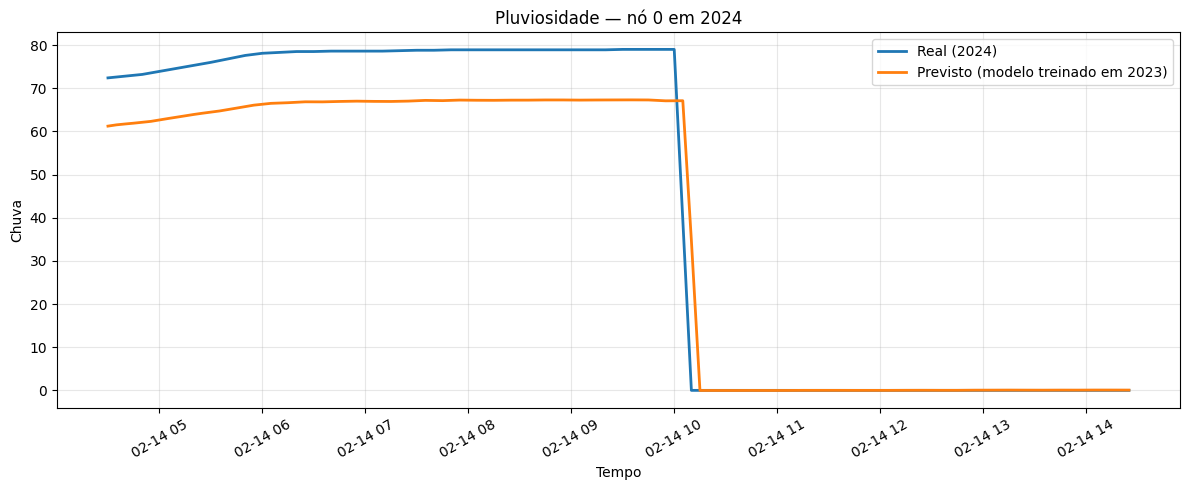

Nó 0 | Pluviosidade | MAE = 0.328615 | RMSE = 1.062480


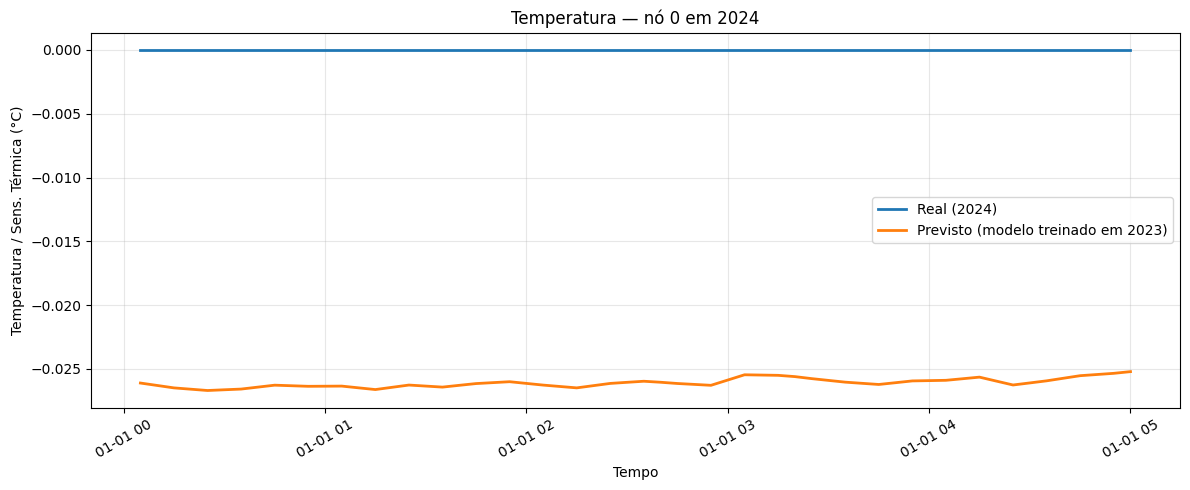

Nó 0 | Temperatura | MAE = 0.024605 | RMSE = 0.025497


In [17]:
def plotar_no_especifico(preds_all, trues_all, timestamps_2024, node_id, nome_variavel, ylabel, criterio_janela="pico_real", window=120):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]
    half_window = window // 2

    if criterio_janela == "pico_real":
        idx_central = int(np.argmax(trues_no))
    else:
        idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))

    start = max(0, idx_central - half_window)
    end = min(len(trues_no), idx_central + half_window)
    tempo_2024 = np.array(timestamps_2024[1:])

    mae = float(np.mean(np.abs(preds_no - trues_no)))
    rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

    plt.figure(figsize=(12, 5))
    plt.plot(tempo_2024[start:end], trues_no[start:end], linewidth=2, label="Real (2024)")
    plt.plot(tempo_2024[start:end], preds_no[start:end], linewidth=2, label="Previsto (modelo treinado em 2023)")
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — nó {node_id} em 2024")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"Nó {node_id} | {nome_variavel} | MAE = {mae:.6f} | RMSE = {rmse:.6f}")

# exemplo:
plotar_no_especifico(preds_chuva_all, trues_chuva_all, timestamps_2024, node_id=0, nome_variavel="Pluviosidade", ylabel="Chuva")
plotar_no_especifico(preds_temp_all, trues_temp_all, timestamps_2024, node_id=0, nome_variavel="Temperatura", ylabel="Temperatura / Sens. Térmica (°C)", criterio_janela="maior_desvio_media")


In [18]:
def obter_indice_no(node_ref, nodes_lista=nodes_lista):
    node_ref_str = str(node_ref)
    nodes_str = [str(n) for n in nodes_lista]

    if node_ref_str in nodes_str:
        return nodes_str.index(node_ref_str)

    if isinstance(node_ref, int) and 0 <= node_ref < len(nodes_lista):
        return node_ref

    raise KeyError(f"Nó {node_ref} não encontrado em nodes_lista.")


def plotar_no_mes(
    preds_all,
    trues_all,
    timestamps,
    node_ref,
    nome_variavel,
    ylabel,
    ano=2024,
    mes=1,
    titulo_real="Referência do experimento cego (média ponderada dos vizinhos)",
    titulo_prev="Previsto pelo modelo"
):
    node_idx = obter_indice_no(node_ref)
    node_label = G.nodes[str(nodes_lista[node_idx])].get("label", "")

    preds_no = preds_all[:, node_idx]
    trues_no = trues_all[:, node_idx]
    tempo = pd.to_datetime(timestamps[1:])

    mask = (tempo.year == ano) & (tempo.month == mes)
    tempo_mes = tempo[mask]
    preds_mes = preds_no[mask]
    trues_mes = trues_no[mask]

    print(f"Nó {node_ref} ({node_label}) | pontos encontrados em {mes:02d}/{ano}: {len(tempo_mes)}")

    if len(tempo_mes) == 0:
        print("Nenhum dado encontrado.")
        return

    mae = float(np.mean(np.abs(preds_mes - trues_mes)))
    rmse = float(np.sqrt(np.mean((preds_mes - trues_mes) ** 2)))

    plt.figure(figsize=(15, 5))
    plt.plot(tempo_mes, trues_mes, linewidth=2, label=titulo_real)
    plt.plot(tempo_mes, preds_mes, linewidth=2, linestyle="--", label=titulo_prev)
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — Nó {node_ref} ({node_label}) — {mes:02d}/{ano}")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"MAE  = {mae:.6f}")
    print(f"RMSE = {rmse:.6f}")


def plotar_nos_cegos_janeiro(
    nos_cegos=("33", "34", "35"),
    ano=2024,
    mes=1
):
    for node_ref in nos_cegos:
        plotar_no_mes(
            preds_all=preds_chuva_all,
            trues_all=trues_chuva_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Pluviosidade",
            ylabel="Chuva (mm)",
            ano=ano,
            mes=mes
        )
        plotar_no_mes(
            preds_all=preds_temp_all,
            trues_all=trues_temp_all,
            timestamps=timestamps_2024,
            node_ref=node_ref,
            nome_variavel="Temperatura",
            ylabel="Temperatura / Sens. Térmica (°C)",
            ano=ano,
            mes=mes
        )


Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 8927


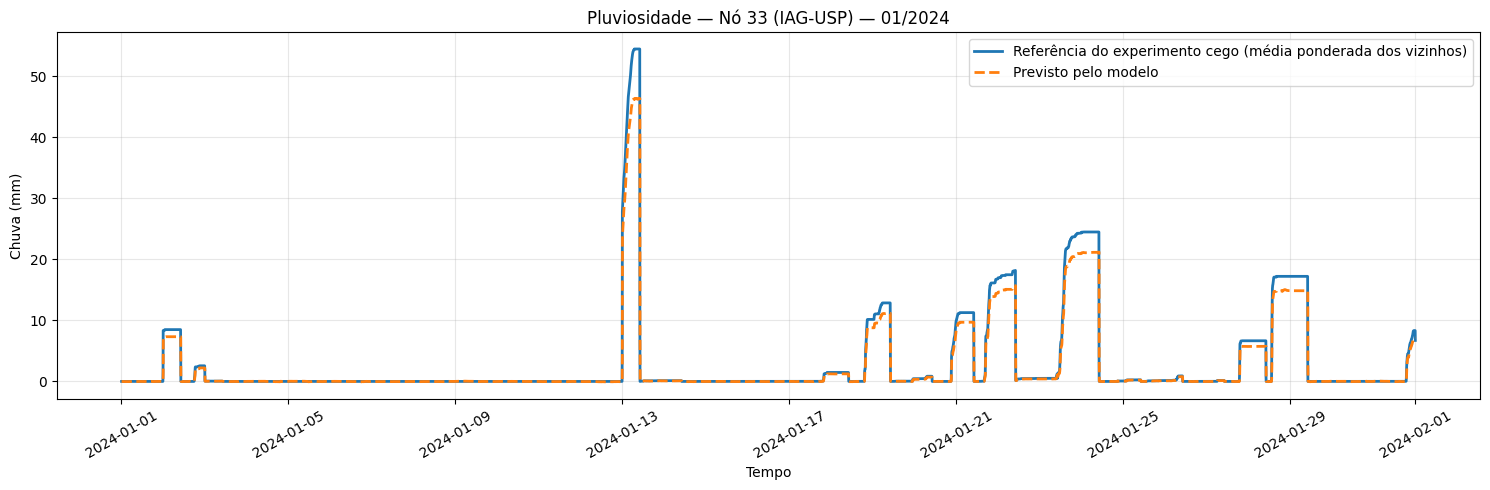

MAE  = 0.452004
RMSE = 1.308363
Nó 33 (IAG-USP) | pontos encontrados em 01/2024: 8927


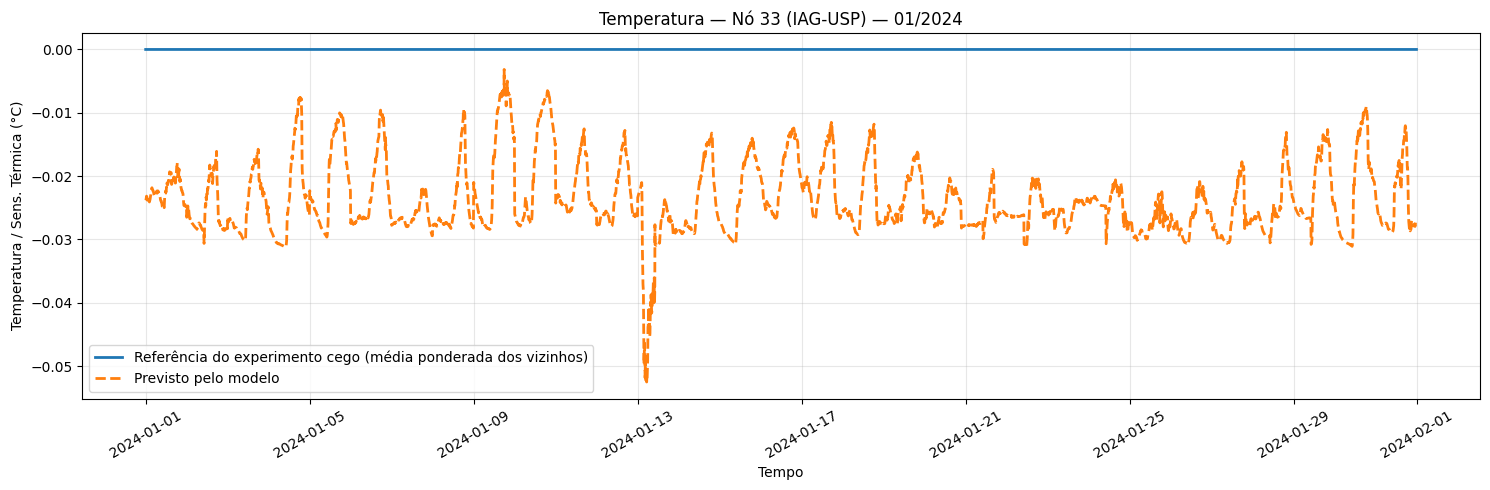

MAE  = 0.023652
RMSE = 0.024351
Nó 34 (INMET - Mirante de Santana) | pontos encontrados em 01/2024: 8927


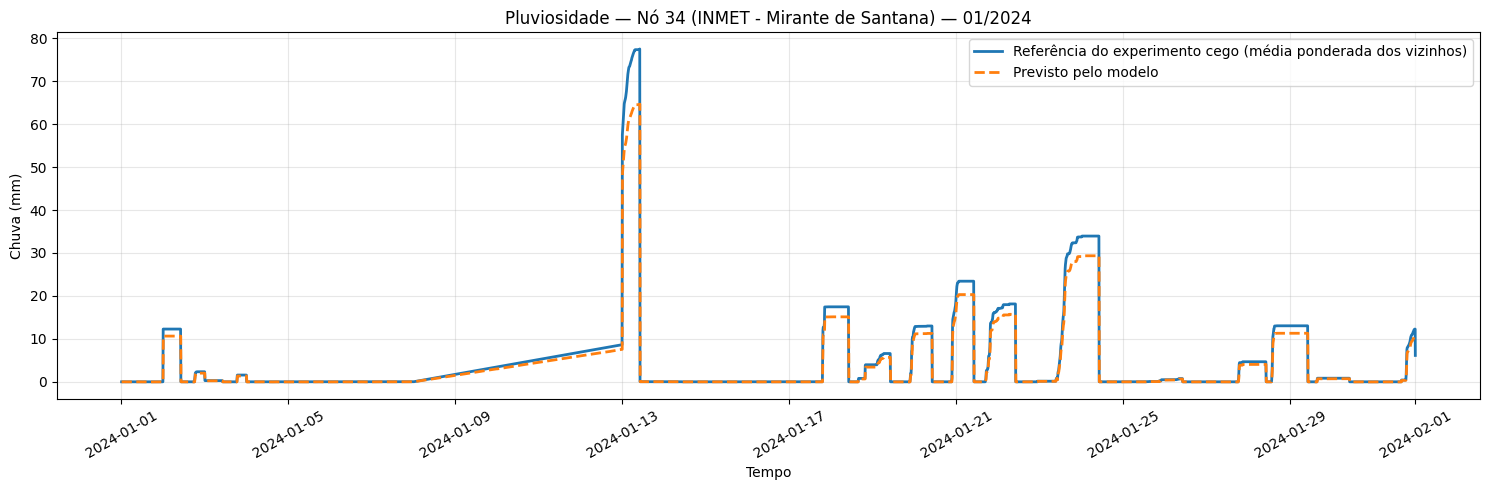

MAE  = 0.709069
RMSE = 1.907030
Nó 34 (INMET - Mirante de Santana) | pontos encontrados em 01/2024: 8927


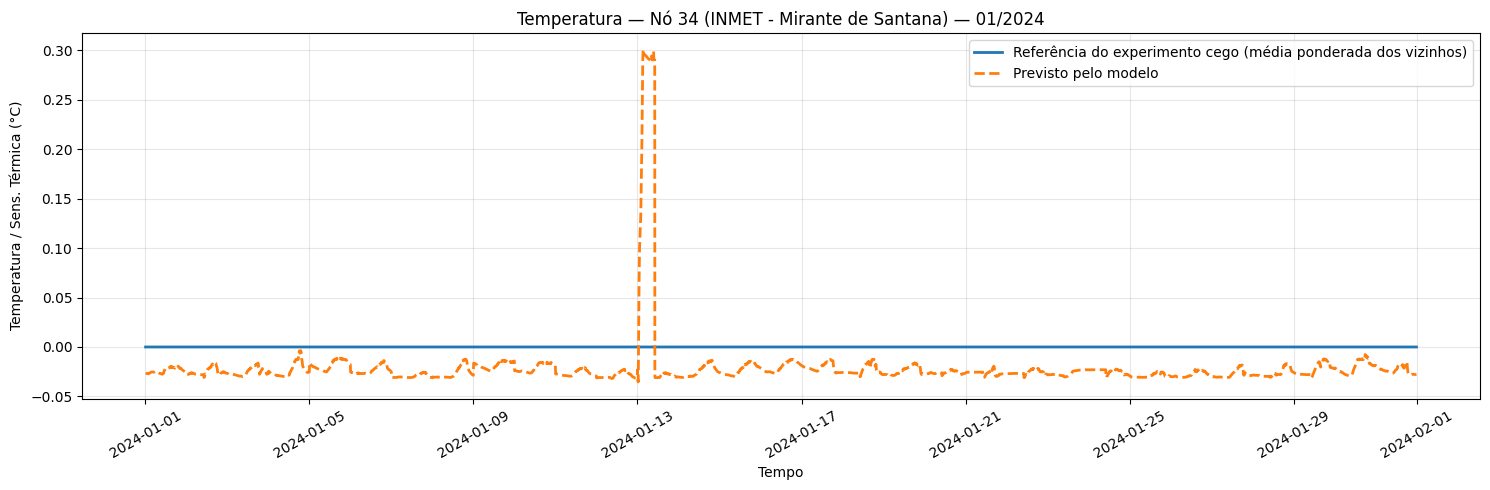

MAE  = 0.027337
RMSE = 0.038857
Nó 35 (INMET - Convencional) | pontos encontrados em 01/2024: 8927


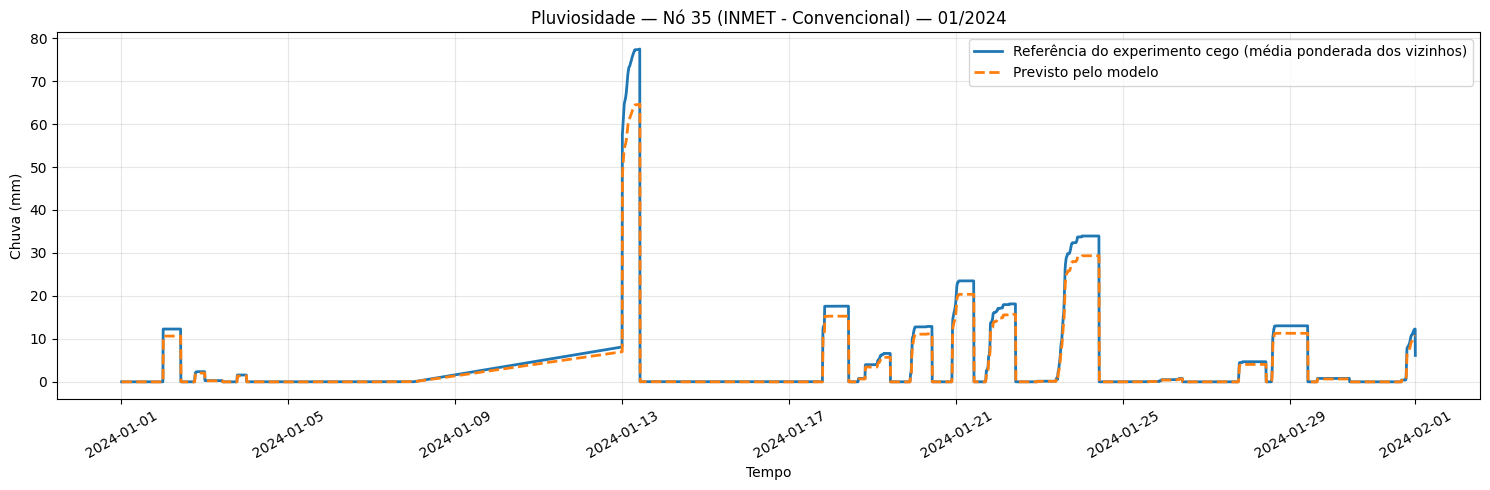

MAE  = 0.710297
RMSE = 1.908730
Nó 35 (INMET - Convencional) | pontos encontrados em 01/2024: 8927


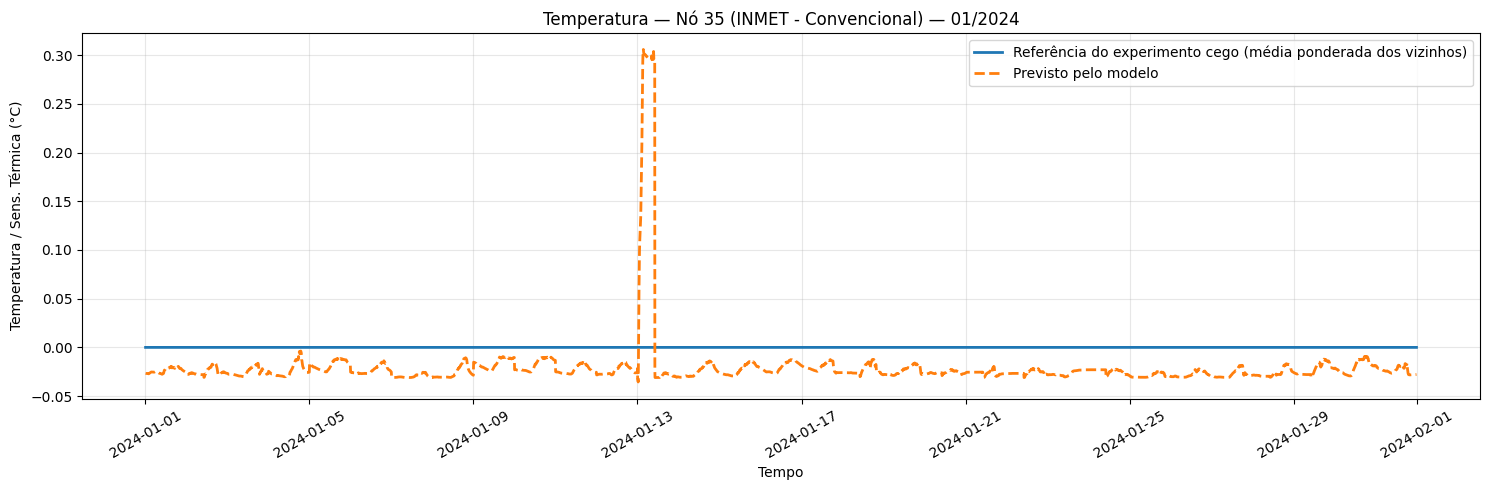

MAE  = 0.026937
RMSE = 0.038998


In [19]:
plotar_nos_cegos_janeiro()


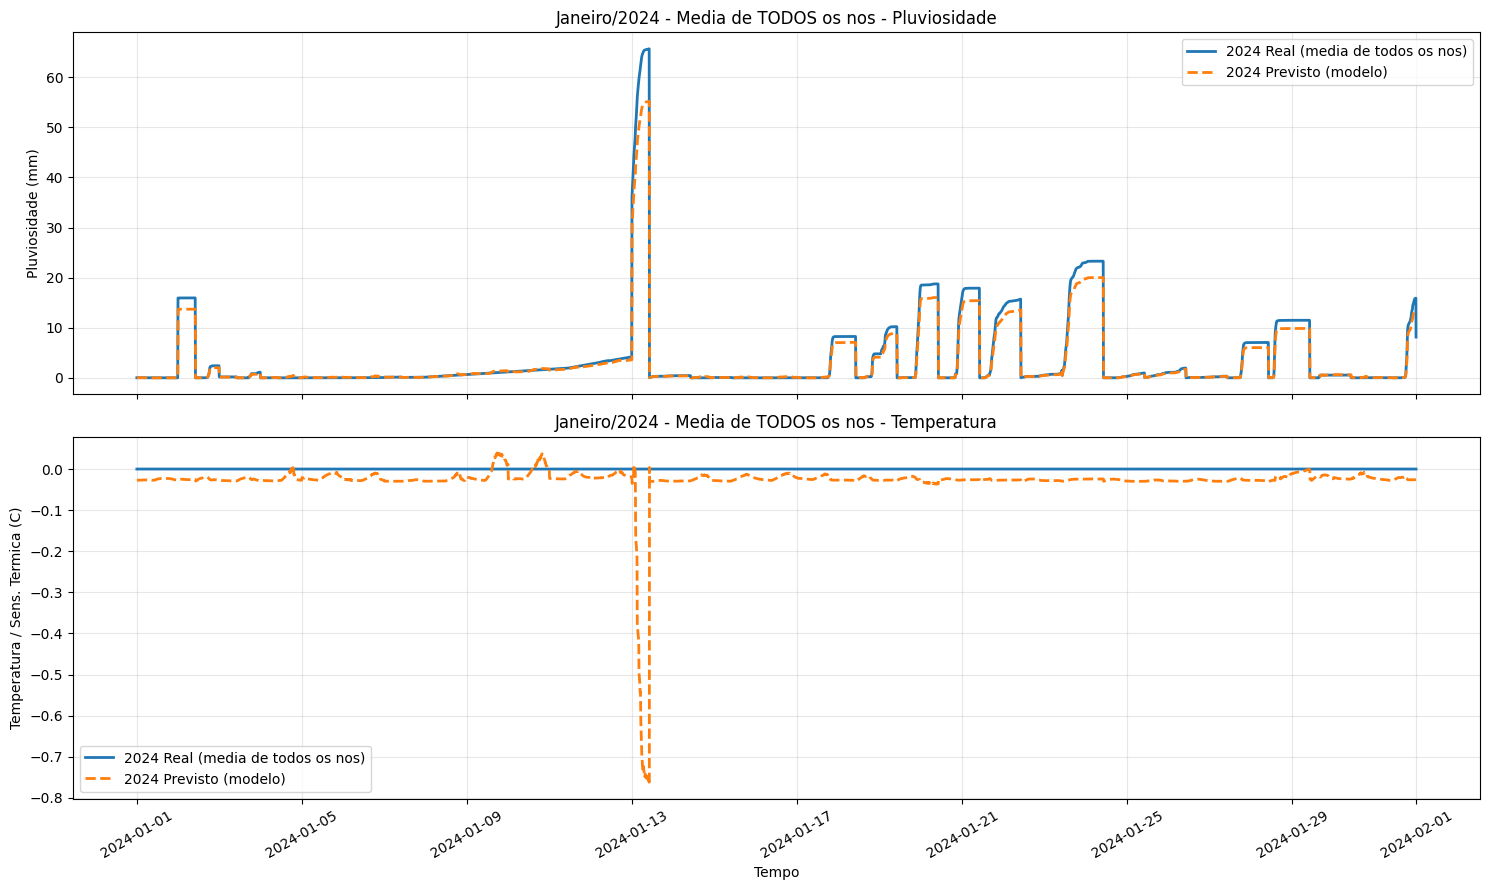


Metricas - Media de TODOS os nos em janeiro/2024
Pluviosidade | MAE = 0.592428 | RMSE = 1.534998
Temperatura  | MAE = 0.030078 | RMSE = 0.069928


In [20]:
def plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all,
    trues_chuva_all,
    preds_temp_all,
    trues_temp_all,
    timestamps_2024
):
    tempo = pd.to_datetime(timestamps_2024[1:])
    mask_jan_2024 = (tempo.year == 2024) & (tempo.month == 1)

    if mask_jan_2024.sum() == 0:
        print("Nenhum ponto encontrado para janeiro de 2024.")
        return

    tempo_jan = tempo[mask_jan_2024]

    media_real_chuva = trues_chuva_all.mean(axis=1)[mask_jan_2024]
    media_prev_chuva = preds_chuva_all.mean(axis=1)[mask_jan_2024]

    media_real_temp = trues_temp_all.mean(axis=1)[mask_jan_2024]
    media_prev_temp = preds_temp_all.mean(axis=1)[mask_jan_2024]

    mae_chuva = float(np.mean(np.abs(media_prev_chuva - media_real_chuva)))
    rmse_chuva = float(np.sqrt(np.mean((media_prev_chuva - media_real_chuva) ** 2)))

    mae_temp = float(np.mean(np.abs(media_prev_temp - media_real_temp)))
    rmse_temp = float(np.sqrt(np.mean((media_prev_temp - media_real_temp) ** 2)))

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

    axes[0].plot(tempo_jan, media_real_chuva, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[0].plot(tempo_jan, media_prev_chuva, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[0].set_ylabel("Pluviosidade (mm)")
    axes[0].set_title("Janeiro/2024 - Media de TODOS os nos - Pluviosidade")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(tempo_jan, media_real_temp, linewidth=2, label="2024 Real (media de todos os nos)")
    axes[1].plot(tempo_jan, media_prev_temp, linewidth=2, linestyle="--", label="2024 Previsto (modelo)")
    axes[1].set_xlabel("Tempo")
    axes[1].set_ylabel("Temperatura / Sens. Termica (C)")
    axes[1].set_title("Janeiro/2024 - Media de TODOS os nos - Temperatura")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    plt.close()

    print("\nMetricas - Media de TODOS os nos em janeiro/2024")
    print(f"Pluviosidade | MAE = {mae_chuva:.6f} | RMSE = {rmse_chuva:.6f}")
    print(f"Temperatura  | MAE = {mae_temp:.6f} | RMSE = {rmse_temp:.6f}")


plotar_media_todos_nos_janeiro_2024(
    preds_chuva_all=preds_chuva_all,
    trues_chuva_all=trues_chuva_all,
    preds_temp_all=preds_temp_all,
    trues_temp_all=trues_temp_all,
    timestamps_2024=timestamps_2024
)
